In [1]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


In [ ]:
SP = ['^GSPC']
SECTORS = ['XLK', 'XLF', 'XLE', 'XLV', 'XLI', 'XLY', 'XLP', 'XLU', 'XLB']


total_market = yf.download(
    SP, 
    start='1963-01-01', 
    end='2026-01-01', 
    auto_adjust=True,
)['Close']

sectors = yf.download(
    SECTORS,
    start='1999-01-01',
    end='2026-01-01',
    auto_adjust=True,
)['Close']
sectors.columns = sectors.columns.get_level_values(0)

total_market = total_market.pct_change().dropna()
total_market = (1 + total_market).resample('ME').prod() - 1

sectors = sectors.pct_change().dropna()
sectors = (1 + sectors).resample('ME').prod() - 1

midterm_dates = pd.to_datetime([
    "1926-11-02", "1930-11-04", "1934-11-06", "1938-11-08", "1942-11-03",
    "1946-11-05", "1950-11-07", "1954-11-02", "1958-11-04", "1962-11-06",
    "1966-11-08", "1970-11-03", "1974-11-05", "1978-11-07", "1982-11-02",
    "1986-11-04", "1990-11-06", "1994-11-08", "1998-11-03", "2002-11-05",
    "2006-11-07", "2010-11-02", "2014-11-04", "2018-11-06", "2022-11-08",
    "2026-11-03",
])


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  9 of 9 completed


Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
1999-01-31,-0.025252,-0.064970,0.017333,3.225424e-03,0.145834,-0.005220,-0.008929,0.050602,0.057762
1999-02-28,0.015544,-0.008596,0.015727,9.003119e-03,-0.099174,-0.010496,-0.027557,0.001147,-0.006257
1999-03-31,0.017989,0.141372,0.032411,2.100463e-02,0.074312,-0.001186,-0.063087,0.026345,0.048647
1999-04-30,0.247126,0.148030,0.070175,1.503759e-01,0.005978,-0.034870,0.096604,0.035715,0.026230
1999-05-31,-0.091014,-0.021583,-0.060304,-1.960754e-02,0.003396,-0.010410,0.011746,-0.030711,-0.045261
...,...,...,...,...,...,...,...,...,...
2025-08-31,0.051864,0.036464,0.030934,2.220446e-16,-0.001104,0.012534,-0.015758,0.053669,0.046561
2025-09-30,-0.024217,-0.003182,0.001062,1.879609e-02,0.075337,-0.023177,0.041236,0.017292,0.035914
2025-10-31,-0.044075,-0.013544,-0.027845,5.381563e-03,0.066771,-0.026668,0.021672,0.036502,0.001210


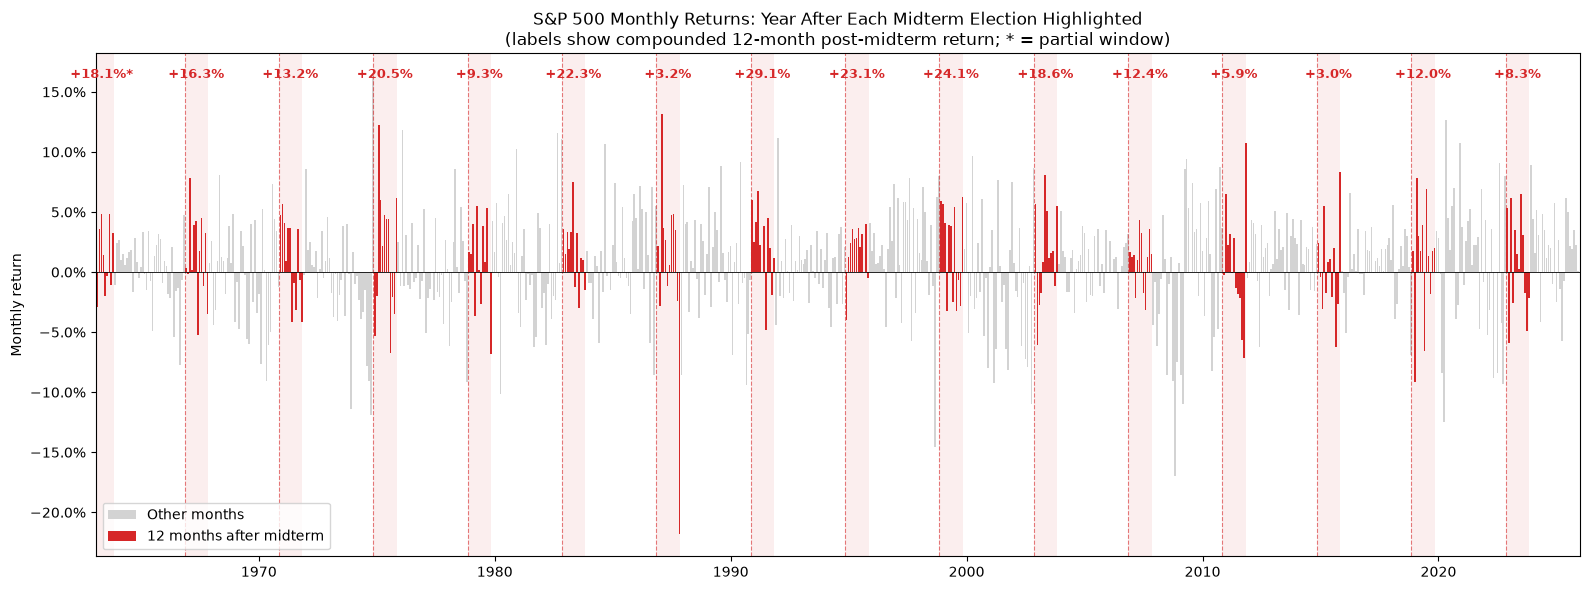

            months return_12m
midterm                      
1962-11-06      10     +18.1%
1966-11-08      12     +16.3%
1970-11-03      12     +13.2%
1974-11-05      12     +20.5%
1978-11-07      12      +9.3%
1982-11-02      12     +22.3%
1986-11-04      12      +3.2%
1990-11-06      12     +29.1%
1994-11-08      12     +23.1%
1998-11-03      12     +24.1%
2002-11-05      12     +18.6%
2006-11-07      12     +12.4%
2010-11-02      12      +5.9%
2014-11-04      12      +3.0%
2018-11-06      12     +12.0%
2022-11-08      12      +8.3%

Mean 12-month post-midterm return (complete windows): +14.8%
Median 12-month post-midterm return:                  +13.2%
Positive post-midterm years:                          15 of 15
Mean of all rolling 12-month returns (baseline):      +8.7%

Mean monthly return, post-midterm months: 1.25%
Mean monthly return, all other months:    0.54%


In [39]:
sp_returns = total_market.squeeze()

# flag months whose month-end falls in the 12 months following a midterm,
# and compound each window into a 12-month post-midterm return
post_midterm = pd.Series(False, index=sp_returns.index)
post_returns = []
for d in midterm_dates:
    window = (sp_returns.index > d) & (sp_returns.index <= d + pd.DateOffset(years=1))
    post_midterm |= window
    if window.any():
        post_returns.append({
            'midterm': d.date(),
            'months': window.sum(),
            'return_12m': (1 + sp_returns[window]).prod() - 1,
        })
post_returns = pd.DataFrame(post_returns).set_index('midterm')

fig, ax = plt.subplots(figsize=(16, 6))

ax.bar(sp_returns.index[~post_midterm], sp_returns[~post_midterm],
       width=25, color='lightgray', label='Other months')
ax.bar(sp_returns.index[post_midterm], sp_returns[post_midterm],
       width=25, color='tab:red', label='12 months after midterm')

for d in midterm_dates:
    if sp_returns.index[0] - pd.DateOffset(years=1) <= d <= sp_returns.index[-1]:
        ax.axvspan(d, d + pd.DateOffset(years=1), color='tab:red', alpha=0.08, lw=0)
        ax.axvline(d, color='tab:red', lw=0.8, ls='--', alpha=0.6)

        # label each window with its compounded return (* = partial window)
        row = post_returns.loc[d.date()]
        label = f"{row['return_12m']:+.1%}" + ('' if row['months'] == 12 else '*')
        ax.text(d + pd.DateOffset(months=6), 0.97, label, transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=9, fontweight='bold', color='tab:red')

ax.axhline(0, color='black', lw=0.6)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(sp_returns.index[0], sp_returns.index[-1])
ax.set_title('S&P 500 Monthly Returns: Year After Each Midterm Election Highlighted\n'
             '(labels show compounded 12-month post-midterm return; * = partial window)')
ax.set_ylabel('Monthly return')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

complete = post_returns[post_returns['months'] == 12]
all_12m = ((1 + sp_returns).rolling(12).apply(lambda x: x.prod(), raw=True) - 1).dropna()

print(post_returns.to_string(formatters={'return_12m': '{:+.1%}'.format}))
print()
print(f"Mean 12-month post-midterm return (complete windows): {complete['return_12m'].mean():+.1%}")
print(f"Median 12-month post-midterm return:                  {complete['return_12m'].median():+.1%}")
print(f"Positive post-midterm years:                          {(complete['return_12m'] > 0).sum()} of {len(complete)}")
print(f"Mean of all rolling 12-month returns (baseline):      {all_12m.mean():+.1%}")
print()
print(f"Mean monthly return, post-midterm months: {sp_returns[post_midterm].mean():.2%}")
print(f"Mean monthly return, all other months:    {sp_returns[~post_midterm].mean():.2%}")

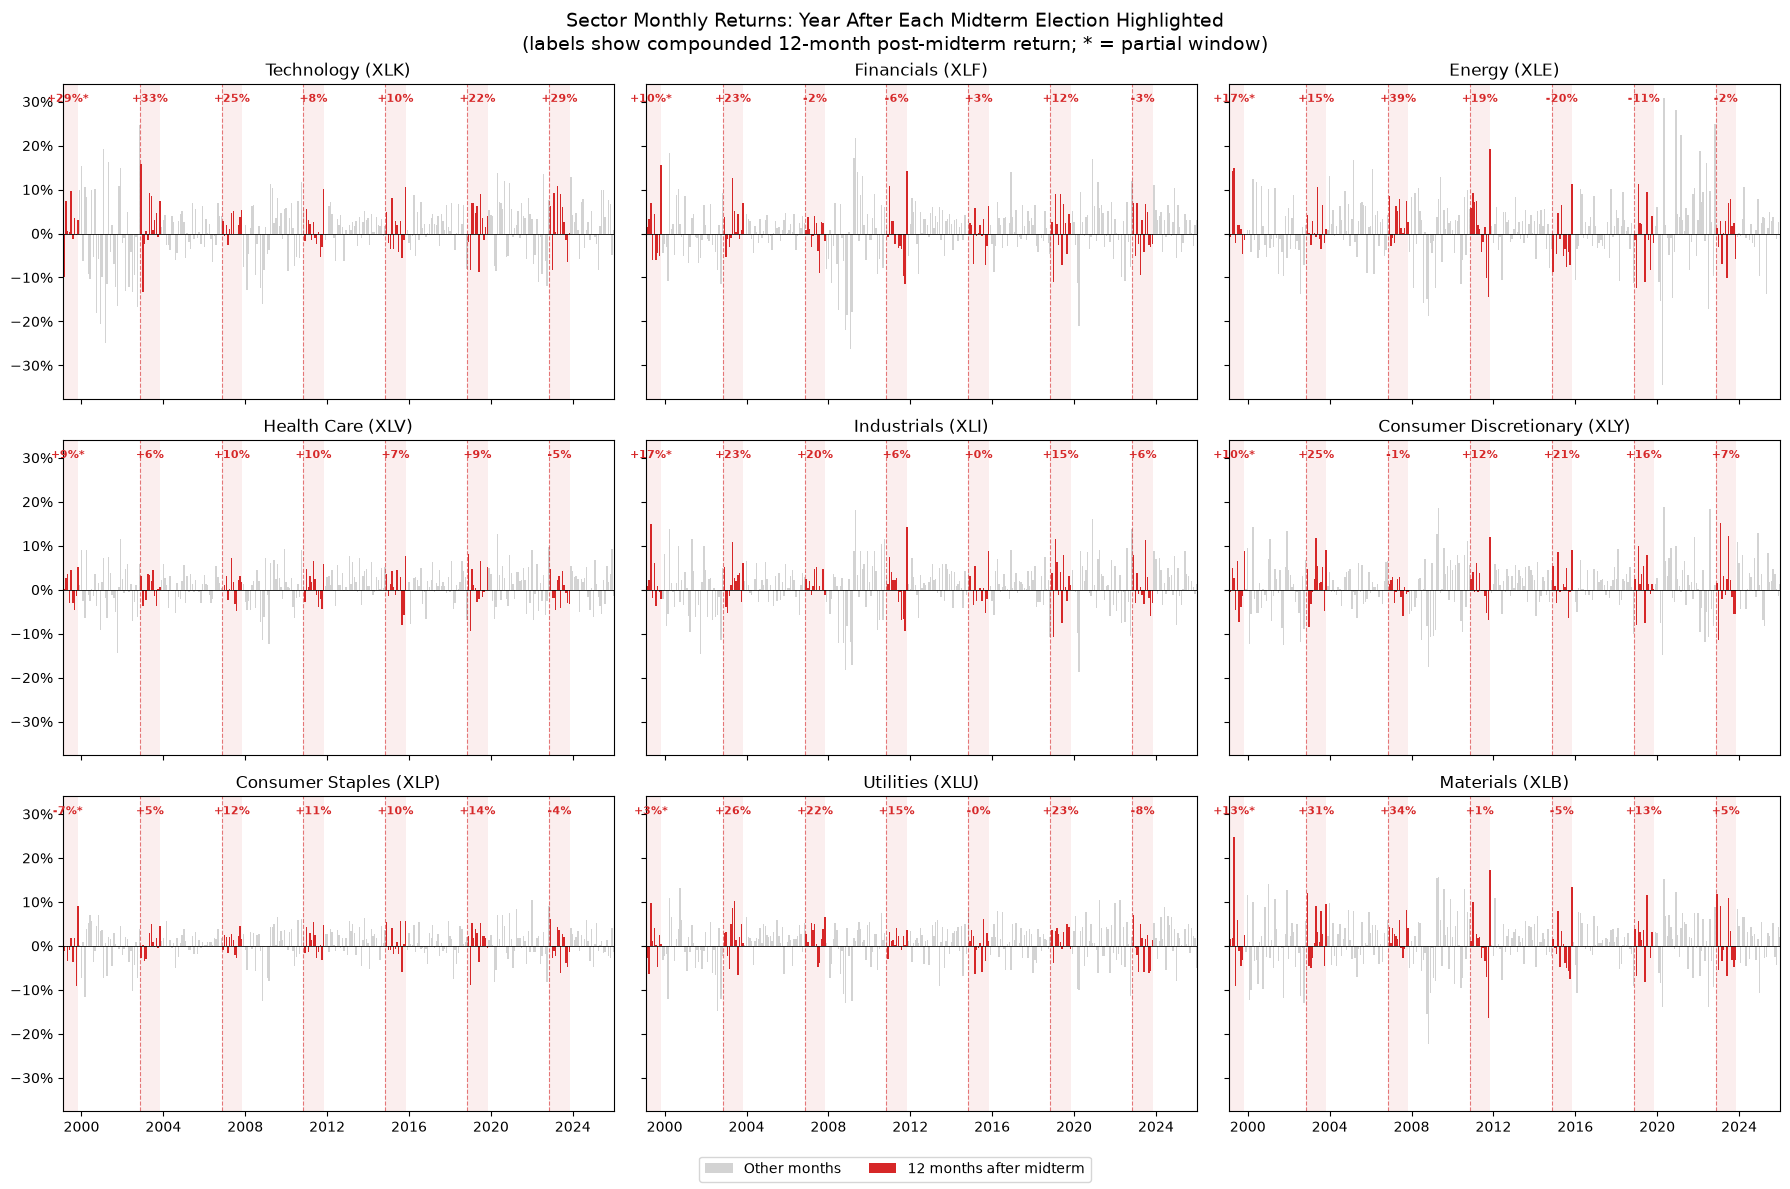

Ticker        XLK    XLF    XLE   XLV    XLI    XLY    XLP    XLU    XLB
midterm                                                                 
1998-11-03 +28.8% +10.0% +17.4% +8.6% +16.9%  +9.7%  -7.1%  +2.7% +13.1%
2002-11-05 +33.3% +22.9% +15.0% +5.5% +22.6% +25.1%  +5.3% +25.8% +30.8%
2006-11-07 +25.2%  -2.4% +39.3% +9.9% +20.4%  -0.6% +12.4% +22.0% +33.6%
2010-11-02  +8.4%  -6.0% +19.5% +9.8%  +6.0% +12.5% +11.0% +14.6%  +1.2%
2014-11-04  +9.7%  +2.8% -20.1% +7.5%  +0.3% +20.6%  +9.6%  -0.3%  -4.5%
2018-11-06 +22.5% +11.6% -10.6% +8.6% +14.8% +16.3% +14.3% +23.5% +13.0%
2022-11-08 +29.5%  -2.8%  -1.8% -4.7%  +6.0%  +6.6%  -4.3%  -7.7%  +4.8%

                             mean_post_midterm median_post_midterm positive mean_all_12m excess_vs_baseline
Technology (XLK)                        +21.4%              +23.8%   6 of 6       +11.9%              +9.5%
Consumer Discretionary (XLY)            +13.4%              +14.4%   5 of 6       +11.2%              +2.2%
Materials (XLB)   

In [38]:
SECTOR_NAMES = {
    'XLK': 'Technology', 'XLF': 'Financials', 'XLE': 'Energy',
    'XLV': 'Health Care', 'XLI': 'Industrials', 'XLY': 'Consumer Discretionary',
    'XLP': 'Consumer Staples', 'XLU': 'Utilities', 'XLB': 'Materials',
}

# same windows as the S&P cell, applied to the sector index
sector_post_midterm = pd.Series(False, index=sectors.index)
sector_post_returns = {}
sector_post_months = {}
for d in midterm_dates:
    window = (sectors.index > d) & (sectors.index <= d + pd.DateOffset(years=1))
    sector_post_midterm |= window
    if window.any():
        sector_post_returns[d.date()] = (1 + sectors[window]).prod() - 1
        sector_post_months[d.date()] = window.sum()
sector_post_returns = pd.DataFrame(sector_post_returns).T[SECTORS]
sector_post_returns.index.name = 'midterm'
sector_post_months = pd.Series(sector_post_months)

fig, axes = plt.subplots(3, 3, figsize=(18, 12), sharex=True, sharey=True)

for ax, ticker in zip(axes.flat, SECTORS):
    r = sectors[ticker]
    ax.bar(r.index[~sector_post_midterm], r[~sector_post_midterm],
           width=25, color='lightgray', label='Other months')
    ax.bar(r.index[sector_post_midterm], r[sector_post_midterm],
           width=25, color='tab:red', label='12 months after midterm')

    for d in sector_post_returns.index:
        d = pd.Timestamp(d)
        ax.axvspan(d, d + pd.DateOffset(years=1), color='tab:red', alpha=0.08, lw=0)
        ax.axvline(d, color='tab:red', lw=0.8, ls='--', alpha=0.6)

        # label each window with its compounded return (* = partial window)
        label = f"{sector_post_returns.loc[d.date(), ticker]:+.0%}"
        label += '' if sector_post_months[d.date()] == 12 else '*'
        ax.text(d + pd.DateOffset(months=6), 0.97, label, transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=8, fontweight='bold', color='tab:red')

    ax.axhline(0, color='black', lw=0.6)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_xlim(sectors.index[0], sectors.index[-1])
    ax.set_title(f'{SECTOR_NAMES[ticker]} ({ticker})')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2)
fig.suptitle('Sector Monthly Returns: Year After Each Midterm Election Highlighted\n'
             '(labels show compounded 12-month post-midterm return; * = partial window)',
             fontsize=14)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

complete_sectors = sector_post_returns[sector_post_months == 12]
all_12m_sectors = ((1 + sectors).rolling(12).apply(lambda x: x.prod(), raw=True) - 1).dropna()

summary = pd.DataFrame({
    'mean_post_midterm': complete_sectors.mean(),
    'median_post_midterm': complete_sectors.median(),
    'positive': (complete_sectors > 0).sum().astype(str) + f' of {len(complete_sectors)}',
    'mean_all_12m': all_12m_sectors.mean(),
})
summary['excess_vs_baseline'] = summary['mean_post_midterm'] - summary['mean_all_12m']
summary.index = [f'{SECTOR_NAMES[t]} ({t})' for t in summary.index]
pct = '{:+.1%}'.format

print(sector_post_returns.to_string(formatters={t: pct for t in SECTORS}))
print()
print(summary.sort_values('mean_post_midterm', ascending=False).to_string(formatters={
    'mean_post_midterm': pct, 'median_post_midterm': pct,
    'mean_all_12m': pct, 'excess_vs_baseline': pct,
}))